In [10]:
import os
import urllib

path = os.getcwd()

print(path)

/home/leon/Documents/ML_PRosjekt


In [11]:
import pandas as pd
from pandas.plotting import scatter_matrix
import numpy as np

def load_bilar():
    csv_path = os.path.join(path, "bil.csv")
    return pd.read_csv("/home/leon/Documents/Kode/Billastar/bilar.csv")

In [12]:
bilar =load_bilar()
bilar = bilar.drop(columns=["Id"])
bilar.info()


<class 'pandas.DataFrame'>
RangeIndex: 16452 entries, 0 to 16451
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Merke      16447 non-null  str  
 1   Modell     16450 non-null  str  
 2   kmStand    16452 non-null  int64
 3   totPris    16452 non-null  int64
 4   modellAar  16452 non-null  int64
 5   vekt       16452 non-null  int64
 6   hk         16452 non-null  int64
 7   kwh        16452 non-null  int64
 8   gir        16431 non-null  str  
 9   motor      13831 non-null  str  
dtypes: int64(6), str(4)
memory usage: 1.3 MB


In [13]:
from datetime import date

cutoff_year = date.today().year - 30

bilar = bilar[
    (bilar["modellAar"] >= cutoff_year)   # drop cars older than 30 years
    & (bilar["totPris"] > 10_000)         # drop prices of 10 000 or less
    & (bilar["totPris"] <= 1_000_000)     # drop prices over 1 000 000
    & (bilar["kmStand"] <= 1_000_000)     # drop mileage over 1 000 000 km
    & (bilar["kwh"] <= 1_000)             # drop battery capacity over 1 000 kWh
    & (bilar["vekt"] <= 3_500)            # drop weight over 3 500 kg
].copy()

print(f"{len(bilar)} cars left")

count = len(bilar)
bilar = bilar.drop_duplicates()
print("droppa "  + str(count - len(bilar)) + " duplikat")

14858 cars left
droppa 18 duplikat


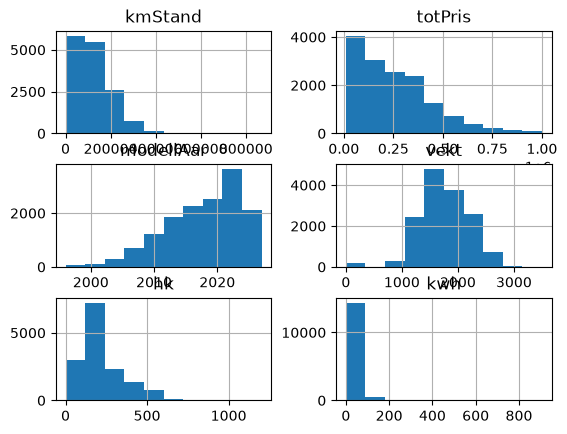

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt
bilar.hist()
plt.show()

In [15]:
bilar.describe()


,kmStand,totPris,modellAar,vekt,hk,kwh
count,14840.000000,14840.000000,14840.000000,14840.000000,14840.000000,14840.000000
mean,121920.775202,256147.280256,2017.584434,1745.342857,222.669474,17.182615
std,81091.819409,191482.354332,5.790932,444.725499,129.744238,32.166281
min,0.000000,10296.000000,1996.000000,0.000000,0.000000,0.000000
25%,59207.500000,99000.000000,2014.000000,1465.750000,131.000000,0.000000
50%,108000.000000,219900.000000,2019.000000,1726.000000,180.000000,0.000000
75%,170000.000000,369000.000000,2022.000000,2075.000000,293.250000,12.000000
max,870000.000000,999999.000000,2027.000000,3500.000000,1202.000000,906.000000


In [16]:
count = len(bilar)
bilar = bilar.drop_duplicates()
print("droppa "  + str(count - len(bilar)) + " duplikat")

droppa 0 duplikat


In [45]:
bilar.describe()

,kmStand,totPris,modellAar,vekt,hk,kwh
count,14840.000000,14840.000000,14840.000000,14840.000000,14840.000000,14840.000000
mean,121920.775202,256147.280256,2017.584434,1745.342857,222.669474,17.182615
std,81091.819409,191482.354332,5.790932,444.725499,129.744238,32.166281
min,0.000000,10296.000000,1996.000000,0.000000,0.000000,0.000000
25%,59207.500000,99000.000000,2014.000000,1465.750000,131.000000,0.000000
50%,108000.000000,219900.000000,2019.000000,1726.000000,180.000000,0.000000
75%,170000.000000,369000.000000,2022.000000,2075.000000,293.250000,12.000000
max,870000.000000,999999.000000,2027.000000,3500.000000,1202.000000,906.000000


In [46]:
from sklearn.model_selection import train_test_split

X = bilar.drop(columns=["totPris"])  
y = bilar["totPris"]                        

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

encoded_train = encoder.fit_transform(X_train[cat_cols])   
encoded_test  = encoder.transform(X_test[cat_cols])        

In [47]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["gir", "motor", "Merke"]

encoder = OneHotEncoder(
    min_frequency=40,                      # categories with fewer than 40 rows are grouped
    handle_unknown="infrequent_if_exist",  # unseen brands also go into the group
    sparse_output=False,
)
encoded = encoder.fit_transform(bilar[cat_cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=[c.replace("infrequent_sklearn", "andre")
             for c in encoder.get_feature_names_out(cat_cols)],
    index=bilar.index,
)

bilar_encoded = pd.concat([bilar.drop(columns=cat_cols), encoded_df], axis=1)

In [48]:

print(X_train.dtypes)

Merke          str
Modell         str
kmStand      int64
modellAar    int64
vekt         int64
hk           int64
kwh          int64
gir            str
motor          str
dtype: object


In [49]:
import numpy as np
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["kmStand", "modellAar", "vekt", "hk", "kwh"]
cat_cols = ["gir", "motor", "Merke"]


X_train_m = X_train.drop(columns=["Modell", "Id"], errors="ignore")
X_test_m  = X_test.drop(columns=["Modell", "Id"], errors="ignore")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(min_frequency=40,
                          handle_unknown="infrequent_if_exist"), cat_cols),
])

model = TransformedTargetRegressor(
    regressor=Pipeline([("prep", preprocess), ("ridge", Ridge(alpha=1.0))]),
    func=np.log1p,
    inverse_func=np.expm1,     
)

model.fit(X_train_m, y_train)
pred = model.predict(X_test_m)

print("MAE (kr):", mean_absolute_error(y_test, pred))
print("R²:", r2_score(y_test, pred))



MAE (kr): 52435.67951025468
R²: 0.7761069948178343


In [50]:
import numpy as np

def success_rate(y_true, y_pred, tolerance=0.05):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return np.mean(np.abs(y_pred - y_true) / y_true <= tolerance)

pred = model.predict(X_test_m)

print(f"Within 5 %:  {success_rate(y_test, pred):.1%}")
print(f"Within 10 %: {success_rate(y_test, pred, 0.10):.1%}")
print(f"Within 20 %: {success_rate(y_test, pred, 0.20):.1%}")



Within 5 %:  16.1%
Within 10 %: 30.9%
Within 20 %: 57.0%


In [51]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import numpy as np

num_cols = ["kmStand", "modellAar", "vekt", "hk", "kwh"]
cat_cols = ["gir", "motor", "Merke"]

preprocess_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(min_frequency=40,
                          handle_unknown="infrequent_if_exist"), cat_cols),
])

tree_model = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", preprocess_tree),
        ("rf", RandomForestRegressor(n_estimators=100, min_samples_leaf=2,
                                     random_state=9, n_jobs=-1)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

tree_model.fit(X_train_m, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...om_state=9))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Merke','kmStand','modellAar',...,'kwh','gir','motor']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,8
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...om_state=9))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('rf', ...)]"


In [52]:
from sklearn.metrics import mean_absolute_error, r2_score

for name, m in [("Linear (Ridge)", model), ("Random forest", tree_model)]:
    pred = m.predict(X_test_m)
    print(f"{name}")
    print(f"  R²:         {r2_score(y_test, pred):.3f}")
    print(f"  MAE (kr):   {mean_absolute_error(y_test, pred):,.0f}")
    print(f"  Within 5 %:  {success_rate(y_test, pred):.1%}")
    print(f"  Within 10 %: {success_rate(y_test, pred, 0.10):.1%}")
    print(f"  Within 20 %: {success_rate(y_test, pred, 0.20):.1%}")

Linear (Ridge)
  R²:         0.776
  MAE (kr):   52,436
  Within 5 %:  16.1%
  Within 10 %: 30.9%
  Within 20 %: 57.0%
Random forest
  R²:         0.917
  MAE (kr):   31,199
  Within 5 %:  30.4%
  Within 10 %: 49.5%
  Within 20 %: 72.7%


In [53]:
train_pred = tree_model.predict(X_train_m)
test_pred  = tree_model.predict(X_test_m)

print(f"Train R²: {r2_score(y_train, train_pred):.3f}")
print(f"Test R²:  {r2_score(y_test, test_pred):.3f}")
print(f"Train within 5 %: {success_rate(y_train, train_pred):.1%}")
print(f"Test within 5 %:  {success_rate(y_test, test_pred):.1%}")

Train R²: 0.977
Test R²:  0.917
Train within 5 %: 50.5%
Test within 5 %:  30.4%


In [54]:
rng = np.random.default_rng(42)

random_pred = rng.choice(y_train.to_numpy(), size=len(y_test), replace=True)

In [55]:
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    "Random guess":   random_pred,
    "Linear (Ridge)": model.predict(X_test_m),
    "Random forest":  tree_model.predict(X_test_m),
}

print(f"{'Model':<16}{'R²':>8}{'MAE (kr)':>12}{'≤5 %':>8}{'≤10 %':>8}{'≤20 %':>8}")
for name, pred in models.items():
    print(f"{name:<16}"
          f"{r2_score(y_test, pred):>8.3f}"
          f"{mean_absolute_error(y_test, pred):>12,.0f}"
          f"{success_rate(y_test, pred):>8.1%}"
          f"{success_rate(y_test, pred, 0.10):>8.1%}"
          f"{success_rate(y_test, pred, 0.20):>8.1%}")

Model                 R²    MAE (kr)    ≤5 %   ≤10 %   ≤20 %
Random guess      -0.908     206,540    3.5%    6.3%   12.3%
Linear (Ridge)     0.776      52,436   16.1%   30.9%   57.0%
Random forest      0.917      31,199   30.4%   49.5%   72.7%


In [56]:
def rule_based_price(X):
    """20 000 kr per model year after 2000, minus the mileage (1 kr per km)."""
    return 20_000 * (X["modellAar"] - 2000) - X["kmStand"]

rule_pred = rule_based_price(X_test_m).to_numpy()

In [60]:
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    "Tilfeldig ":   random_pred,
    "År - KMstand":  rule_pred,
    "Linear (Ridge)": model.predict(X_test_m),
    "Random forest":  tree_model.predict(X_test_m),
}

print(f"{'Model':<16}{'R²':>8}{'MAE (kr)':>12}{'≤5 %':>8}{'≤10 %':>8}{'≤20 %':>8}")
for name, pred in models.items():
    print(f"{name:<16}"
          f"{r2_score(y_test, pred):>8.3f}"
          f"{mean_absolute_error(y_test, pred):>12,.0f}"
          f"{success_rate(y_test, pred):>8.1%}"
          f"{success_rate(y_test, pred, 0.10):>8.1%}"
          f"{success_rate(y_test, pred, 0.20):>8.1%}")

Model                 R²    MAE (kr)    ≤5 %   ≤10 %   ≤20 %
Tilfeldig         -0.908     206,540    3.5%    6.3%   12.3%
År - KMstand       0.373     108,741    9.0%   16.4%   30.5%
Linear (Ridge)     0.776      52,436   16.1%   30.9%   57.0%
Random forest      0.917      31,199   30.4%   49.5%   72.7%


In [58]:
import joblib

joblib.dump(tree_model, "bil_forest.joblib", compress=3)


cats = tree_model.regressor_.named_steps["prep"].named_transformers_["cat"].categories_
print(dict(zip(["gir", "motor", "Merke"], cats)))

import sklearn
print(sklearn.__version__)

{'gir': array(['automat', 'manuell', nan], dtype=object), 'motor': array(['bensin', 'diesel', 'el', nan], dtype=object), 'Merke': array(['Abarth', 'Alfa Romeo', 'Aston Martin', 'Audi', 'BMW', 'BYD',
       'Bentley', 'Buddy', 'Cadillac', 'Changan', 'Chevrolet', 'Chrysler',
       'Citroen', 'Cupra', 'DS', 'Dacia', 'Daihatsu', 'Dodge', 'Dongfeng',
       'Fiat', 'Ford', 'GMC', 'Honda', 'Hongqi', 'Hummer', 'Hyundai',
       'Isuzu', 'Iveco', 'JAC', 'Jaguar', 'Jeep', 'KGM', 'Kia',
       'Lamborghini', 'Lancia', 'Land Rover', 'Leapmotor', 'Lexus',
       'Lotus', 'MAN', 'MG', 'MINI', 'Maserati', 'Maxus', 'Mazda',
       'Mercedes-Benz', 'Micro', 'Mitsubishi', 'NIO', 'Nissan', 'Opel',
       'Peugeot', 'Polestar', 'Porsche', 'RAM', 'Renault', 'Rover',
       'Saab', 'Seat', 'Seres', 'Skoda', 'Smart', 'SsangYong', 'Subaru',
       'Suzuki', 'Tesla', 'Toyota', 'VOYAH', 'Volkswagen', 'Volvo',
       'XPeng', 'Zeekr', nan], dtype=object)}
1.9.1
